# Semi-supervised learning with pseudo-labels (threshold 0.90)

The second half of the project's central question: **can unlabeled reviews improve the classifier?**

20% of the labeled training reviews of each recommendation class had their labels hidden by the project's fixed rule
(`MASK_SEED = "digikala-semi-supervised-v1"`, notebook 01 and `reports/split_manifest.json`). Their texts are the
unlabeled pool, `train_pseudo_unlabeled`. The experiment, as the project defines it, on the recommendation head:

1. **Supervised model (the teacher):** FaBERT fine-tuned on `train_supervised` (notebook 03).
2. **Pseudo-labels:** the teacher's most probable class for each hidden review, from its own softmax, accepted only
   when that probability is at least **0.90** (fixed by the project; not tuned).
3. **Semi-supervised model (the student):** a copy of the teacher, fine-tuned further on `train_supervised` plus the
   accepted pseudo-labeled reviews; they count only for the recommendation loss.
4. **Comparison** of the supervised and the semi-supervised model on the same validation and test sets.

The hidden reviews' true labels (`data/splits/audit/masked_labels_reference.csv`) were read only after training, to
measure how good the pseudo-labels were. No validation or test label made or chose a pseudo-label.

Plan with expected outcomes, written before running: `reports/semi_supervised_official_plan.md`. Nothing is trained
here; every number is read from `reports/`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from digikala_reviews import plotting
from digikala_reviews.config import PSEUDO_LABEL_THRESHOLD, RECOMMENDATION_CLASSES, REPORTS_DIR
from digikala_reviews.tfidf import HEADS

plotting.apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.4f}")
HEAD_TITLES = {"recommendation": "Recommendation", "rating_band": "Rating band"}


def load_report(name):
    return json.loads((REPORTS_DIR / name).read_text(encoding="utf-8"))


semi = load_report("semi_supervised.json")
teacher = load_report("semi_supervised/teacher.json")
student = load_report("semi_supervised/student.json")
control = load_report("semi_supervised/control.json")
final = load_report("final_evaluation.json")["heads"]
manifest = load_report("split_manifest.json")
print(f"Threshold: {PSEUDO_LABEL_THRESHOLD}")

Threshold: 0.9


## 1. The data

In [2]:
supervised_rec = manifest["class_counts"]["train_supervised.csv"]["recommendation_status"]
masked = manifest["masking"]["per_class"]
pd.DataFrame(
    {
        "labeled in train_supervised": {c: supervised_rec[c] for c in RECOMMENDATION_CLASSES},
        "hidden (train_pseudo_unlabeled)": {c: masked[c]["masked"] for c in RECOMMENDATION_CLASSES},
    }
).assign(**{"hidden share": lambda t: t.iloc[:, 1] / (t.iloc[:, 0] + t.iloc[:, 1])})

,labeled in train_supervised,hidden (train_pseudo_unlabeled),hidden share
recommended,2329622,582405,0.2000
not_recommended,282488,70622,0.2000
no_idea,332429,83107,0.2000


Exactly 20% of each class is hidden (rounded down), so the hidden pool has the class shares of the training labels:
79% `recommended`, 11% `no_idea`, 10% `not_recommended`.

## 2. The pseudo-labels

The teacher (the kept FaBERT run, weights checked by their hash) scored all 736,134 hidden reviews. Its own softmax
was used, with no temperature and no offsets.

In [3]:
quality = semi["pseudo_labels"]
rows = []
for t in ("0.8", "0.9", "0.95"):
    q = quality[t]
    rows.append(
        {
            "threshold": float(t),
            "used": "yes" if float(t) == PSEUDO_LABEL_THRESHOLD else "report only",
            "accepted": q["kept"],
            "accepted share": q["share_kept"],
            "accepted right": q["accuracy"],
            **{f"share {c}": q["kept_classes"].get(c, 0.0) for c in RECOMMENDATION_CLASSES},
        }
    )
pd.DataFrame(rows).set_index("threshold")

,used,accepted,accepted share,accepted right,share recommended,share not_recommended,share no_idea
threshold,,,,,,,
0.8000,report only,587492,0.7981,0.9553,0.9255,0.0690,0.0055
0.9000,yes,533043,0.7241,0.9690,0.9494,0.0498,0.0008
0.9500,report only,445123,0.6047,0.9802,0.9639,0.0361,0.0000


In [4]:
reference = quality["reference_class_shares"]
q = quality[str(PSEUDO_LABEL_THRESHOLD)]
pd.DataFrame(
    {
        "true share among the hidden reviews": reference,
        "share among the accepted pseudo-labels": q["kept_classes"],
        "hidden reviews of this class accepted with the right label": q["kept_right_per_true_class"],
    }
).loc[RECOMMENDATION_CLASSES]

,true share among the hidden reviews,share among the accepted pseudo-labels,hidden reviews of this class accepted with the right label
recommended,0.7912,0.9494,0.8441
not_recommended,0.0959,0.0498,0.3471
no_idea,0.1129,0.0008,0.0044


At 0.90, **72.4% of the hidden reviews (533,043) were accepted, and 96.9% of them are right.** But the accepted
pseudo-labels are 94.9% `recommended`, 5.0% `not_recommended` and only 0.1% `no_idea`. Of the hidden `no_idea`
reviews, 0.4% got the right pseudo-label; of the hidden `not_recommended` ones, 34.7%. The confident guesses are
mostly reviews of the class the model already knows best. A lower threshold (0.80) would let more of the smaller
classes in, at a lower accuracy; the threshold is fixed by the project and was not changed.

## 3. The student, and a control

The student is the teacher fine-tuned for **one more epoch** on `train_supervised` plus the 533,043 accepted reviews
(4,085,541 reviews), with exactly the teacher's settings and seed. One more epoch could change the model by itself,
with or without pseudo-labels, so a **control** was trained the same way on `train_supervised` alone. The
difference between the student and the control is the effect of the pseudo-labels.

Both were checked four times during the epoch on the same 50,000-review validation sample as the teacher; the
starting model is check 0.

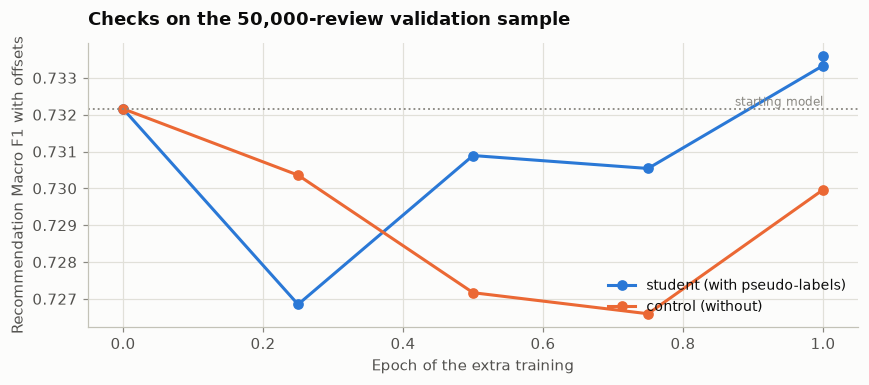

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for name, run, color in [
    ("student (with pseudo-labels)", student, plotting.SERIES[0]),
    ("control (without)", control, plotting.SERIES[1]),
]:
    checks = run["checks"]
    ax.plot(
        [c["epoch"] for c in checks],
        [c["recommendation_macro_f1"] for c in checks],
        marker="o",
        color=color,
        label=name,
    )
ax.axhline(
    student["checks"][0]["recommendation_macro_f1"], color=plotting.MUTED, linestyle=":", linewidth=1.2
)
ax.text(
    1.0,
    student["checks"][0]["recommendation_macro_f1"],
    " starting model",
    va="bottom",
    ha="right",
    fontsize=8,
    color=plotting.MUTED,
)
ax.set_xlabel("Epoch of the extra training")
ax.set_ylabel("Recommendation Macro F1 with offsets")
ax.set_title("Checks on the 50,000-review validation sample")
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

No check of either run beat the starting model. The model was already at its best (notebook 03: the teacher was kept
at epoch 2.75, and its validation loss rose after epoch 3), and one more epoch at the same learning rate made it a
little worse, **with or without pseudo-labels**. By the rule written before the run, both would keep check 0, which
is the teacher itself. So that the comparison the project asks for is not between a model and itself, the weights at
the **end** of the extra epoch were kept too: that is the model the semi-supervised training actually made, and it is
the semi-supervised model compared below and on the test set (added to the plan before the second run).

## 4. Validation: supervised, control and student

The whole validation set, recommendation head, with offsets (`reports/semi_supervised.json`).

In [6]:
names = {
    "supervised": "supervised (teacher)",
    "control at the end": "control, end of epoch",
    "student at the end": "student, end of epoch (semi-supervised)",
}
rows = []
for key, name in names.items():
    m = semi["heads"]["recommendation"]["models"][key]["with_offsets"]
    rows.append(
        {
            "model": name,
            "accuracy": m["accuracy"],
            "Macro F1": m["macro_f1"],
            "Macro precision": m["macro_precision"],
            "Macro recall": m["macro_recall"],
            **{f"F1 {c}": m["per_class"][c]["f1"] for c in RECOMMENDATION_CLASSES},
        }
    )
pd.DataFrame(rows).set_index("model")

,accuracy,Macro F1,Macro precision,Macro recall,F1 recommended,F1 not_recommended,F1 no_idea
model,,,,,,,
supervised (teacher),0.8736,0.7324,0.7346,0.7320,0.9441,0.7436,0.5096
"control, end of epoch",0.8731,0.7300,0.7342,0.7278,0.9440,0.7393,0.5067
"student, end of epoch (semi-supervised)",0.8756,0.7310,0.7359,0.7268,0.9453,0.7444,0.5032


In [7]:
rows = []
for head in HEADS:
    for pair in [
        "student at the end minus control at the end",
        "student at the end minus supervised",
        "control at the end minus supervised",
    ]:
        d = semi["heads"][head]["differences_with_offsets"][pair]
        low, high = d["interval_95_products"]
        rows.append(
            {
                "head": head,
                "comparison": pair.replace(" at the end", ", end of epoch"),
                "Macro F1 difference (points)": 100 * d["difference"],
                "95% interval (points)": f"[{100 * low:+.2f}, {100 * high:+.2f}]",
            }
        )
pd.DataFrame(rows)

,head,comparison,Macro F1 difference (points),95% interval (points)
0,recommendation,"student, end of epoch minus control, end of epoch",0.0952,"[+0.02, +0.17]"
1,recommendation,"student, end of epoch minus supervised",-0.1468,"[-0.23, -0.07]"
2,recommendation,"control, end of epoch minus supervised",-0.2420,"[-0.33, -0.16]"
3,rating_band,"student, end of epoch minus control, end of epoch",0.1835,"[+0.12, +0.25]"
4,rating_band,"student, end of epoch minus supervised",-0.0093,"[-0.07, +0.06]"
5,rating_band,"control, end of epoch minus supervised",-0.1929,"[-0.26, -0.13]"


On validation the extra epoch costs the control 0.24 point; with the pseudo-labels the student loses less (0.15
point), so the pseudo-labels soften the drop by 0.10 point, but the student stays below the supervised model. The
rule fixed before the run (the student must beat the control by more than 0.12 point, the spread between seeds,
with the whole interval above zero) gives: **no measurable gain**.

## 5. Test: the supervised and the semi-supervised model

The comparison the project asks for: every required score of both models on the same test set, and the change after
adding the pseudo-labeled data. From the single reading of the test set (`reports/final_evaluation.json`).

In [8]:
for head in HEADS:
    rows = {}
    for key, name in [("fabert", "supervised"), ("student", "semi-supervised")]:
        m = final[head]["models"][key]["with_offsets"]
        row = {
            "accuracy": m["accuracy"],
            "Macro F1": m["macro_f1"],
            "Macro precision": m["macro_precision"],
            "Macro recall": m["macro_recall"],
            "balanced accuracy": m["balanced_accuracy"],
        }
        for c in HEADS[head]["labels"]:
            for k in ("precision", "recall", "f1"):
                row[f"{c} {k}"] = m["per_class"][c][k]
        rows[name] = row
    table = pd.DataFrame(rows)
    table["change (points)"] = 100 * (table["semi-supervised"] - table["supervised"])
    low, high = final[head]["differences"]["student minus fabert"]["macro_f1_interval_95_products"]
    print(f"{HEAD_TITLES[head]}: Macro F1 change, 95% interval [{100 * low:+.2f}, {100 * high:+.2f}] points")
    display(table)

Recommendation: Macro F1 change, 95% interval [-0.25, -0.08] points


,supervised,semi-supervised,change (points)
accuracy,0.8732,0.8756,0.2412
Macro F1,0.7346,0.7330,-0.1598
Macro precision,0.7338,0.7382,0.4346
Macro recall,0.7374,0.7292,-0.8231
balanced accuracy,0.7374,0.7292,-0.8231
recommended precision,0.9498,0.9455,-0.4282
recommended recall,0.9373,0.9447,0.7423
recommended f1,0.9435,0.9451,0.1612
not_recommended precision,0.7694,0.7772,0.7814
not_recommended recall,0.7236,0.7139,-0.9700


Rating band: Macro F1 change, 95% interval [-0.14, -0.00] points


,supervised,semi-supervised,change (points)
accuracy,0.7941,0.7916,-0.2484
Macro F1,0.6918,0.6911,-0.0638
Macro precision,0.7040,0.7031,-0.0934
Macro recall,0.6810,0.6807,-0.0211
balanced accuracy,0.6810,0.6807,-0.0211
low precision,0.7496,0.7525,0.2976
low recall,0.6748,0.6716,-0.3187
low f1,0.7102,0.7098,-0.0443
medium precision,0.4850,0.4785,-0.6518
medium recall,0.4720,0.4796,0.7609


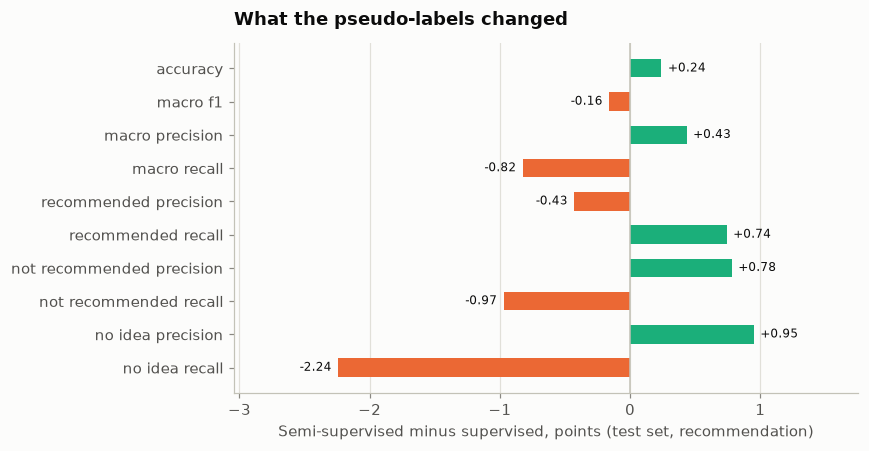

In [9]:
change = final["recommendation"]["differences"]["student minus fabert"]["change"]
keys = ["accuracy", "macro_f1", "macro_precision", "macro_recall"] + [
    f"{c} {k}" for c in RECOMMENDATION_CLASSES for k in ("precision", "recall")
]
values = [100 * change[k] for k in keys]
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(keys))
ax.barh(y, values, height=0.55, color=[plotting.SERIES[2] if v > 0 else plotting.SERIES[1] for v in values])
for i, v in enumerate(values):
    ax.text(
        v + (0.05 if v >= 0 else -0.05),
        i,
        f"{v:+.2f}",
        va="center",
        ha="left" if v >= 0 else "right",
        fontsize=8,
    )
ax.axvline(0, color=plotting.AXIS, linewidth=1)
ax.set_yticks(y, [k.replace("_", " ") for k in keys])
ax.invert_yaxis()
ax.set_xlim(min(values) - 0.8, max(values) + 0.8)
ax.set_xlabel("Semi-supervised minus supervised, points (test set, recommendation)")
ax.grid(axis="y", visible=False)
ax.set_title("What the pseudo-labels changed")
fig.tight_layout()
plt.show()

On the test set the semi-supervised model is **0.16 point worse in Macro F1** on recommendation (interval
[-0.25, -0.08]), while its **accuracy is 0.24 point higher**. The picture explains why: recall of `recommended` rises
and recall of `no_idea` falls by 2.2 points (and of `not_recommended` by 1.0), while their precision rises. The
pseudo-labels, almost all `recommended`, pull the model towards that class. Accuracy counts mostly the large class,
Macro F1 counts every class equally, so they move in opposite directions. The rating band, which saw no
pseudo-labels, is almost unchanged (-0.06 point).

The same happened on validation and in the earlier pilot (`reports/semi_supervised_plan.md`: 500,000 reviews,
pseudo-labels from temperature-scaled probabilities, a tie within the spread between seeds), so the result does not
depend on one run.

## 6. Conclusions

1. **The pseudo-labels are accurate but one-sided.** At 0.90, 72.4% of the hidden reviews were accepted and 96.9% of
   those are right, but 94.9% of them are `recommended` and only 0.1% `no_idea`.
2. **They do not improve the classifier.** The semi-supervised model is 0.16 point below the supervised one in Macro
   F1 on the test set (measurable), and 0.15 point below on validation. By the rule fixed before the run, the answer
   is **no measurable gain**.
3. **They change the balance between classes.** Accuracy rises (+0.24 point) because the model leans towards
   `recommended`; `no_idea` loses 2.2 points of recall. For a task scored by Macro F1 this is a loss.
4. **The control shows why the comparison needs one.** One more epoch alone costs 0.24 point; the pseudo-labels
   soften that by 0.10 point but do not turn it into a gain.
5. **Answer to the central question:** for this model, these data and the project's fixed protocol, the unlabeled
   reviews do **not** improve the classifier. The model is already trained on about 3 million labeled reviews, and the
   reviews it is confident about are the ones it already gets right; the hard reviews (`no_idea`) are exactly those
   it is not confident about, so they never become pseudo-labels.